In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(7);
tf.random.set_seed(7)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [11]:
num_notes       = 40     # vocabulary size (given)
sequence_length = 25     # notes per melody (given)
num_sequences   = 1200   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)
print("Data Shape:",data.shape)
# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data[:,:-1]   # TODO (Q1a): data[:, :-1]
y_train = data[:, 1:]   # TODO (Q1a): data[:, 1:]

# Q1b) one-hot encode both to shape
NUM_CLASSES = 40   # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

Data Shape: (1200, 25)
x_train: (1200, 24, 40)  y_train: (1200, 24, 40)


Q. What do the two numbers in data.shape mean (rows vs columns)?
* **Answer**: The first number (`1200`) represents the number of independent melodies (samples), and the second number (`25`) represents the number of sequential notes (timesteps) in each melody.

Q. Why is the target the input shifted by one? What task does that set up?
* **Answer**: Shifting the target by one timestep means that at any given timestep $t$, the model's goal is to predict the next note (which is the input at timestep $t+1$). This sets up the task of **autoregressive sequence prediction** (next-step prediction).

In [12]:
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))

# Q2a) first Bidirectional LSTM: 128 units, return a sequence
model.add(layers.Bidirectional(layers.LSTM(100, return_sequences=True)))  # TODO (Q2a)

# Q2b) second Bidirectional LSTM: same settings
model.add(layers.Bidirectional(layers.LSTM(100, return_sequences=True)))   # TODO (Q2b): another Bidirectional(LSTM(128, return_sequences=True))

# Q2c) TimeDistributed Dense output: one softmax classifier per step
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))  # TODO (Q2c)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

Q. Each LSTM has 100 units, yet each Bidirectional layer outputs 200 features per step —why? And what does TimeDistributed do with the Dense layer?
* **Answer**: A bidirectional layer processes the sequence in both forward and backward directions using two separate LSTMs of 100 units each. The final output features at each step are concatenated from both passes ($100 + 100 = 200$).
* `TimeDistributed` applies the exact same Dense layer independently to every individual timestep of the 3D tensor output, ensuring we get a softmax probability distribution over the 40 classes at every step of the sequence.

In [13]:
# Q3a) compile for multi-class, one-hot targets
model.compile(optimizer=Adam(learning_rate=0.001),   # TODO (Q3a): 0.001
              loss='categorical_crossentropy',                             # TODO (Q3a): 'categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a 20% validation split
history = model.fit(x_train, y_train,
                    epochs=15,            # TODO (Q3b): 15
                    batch_size=64,        # TODO (Q3b): 64
                    validation_split=0.2)  # TODO (Q3b): 0.2

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 364ms/step - accuracy: 0.1144 - loss: 3.6590 - val_accuracy: 0.1828 - val_loss: 3.6189
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 173ms/step - accuracy: 0.1662 - loss: 3.5377 - val_accuracy: 0.1142 - val_loss: 3.4200
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 168ms/step - accuracy: 0.1400 - loss: 3.2706 - val_accuracy: 0.1495 - val_loss: 3.1492
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.1849 - loss: 2.9529 - val_accuracy: 0.2033 - val_loss: 2.8182
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 253ms/step - accuracy: 0.2474 - loss: 2.5791 - val_accuracy: 0.2795 - val_loss: 2.4253
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 163ms/step - accuracy: 0.3254 - loss: 2.1908 - val_accuracy: 0.3606 - val_loss: 2.0332
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 170ms/step - accuracy: 0.4107 - loss: 1.8246 - val_accuracy: 0.4453 - val_loss: 1.6859
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 194ms/step - accuracy: 0.5046 - loss: 1.4934 - val_accuracy: 0

Q. Why is categorical_crossentropy the correct loss here (think about the one-hot targets)?
* **Answer**: Because this is a multi-class classification problem (predicting 1 of 40 discrete notes at each step) and the targets are encoded as one-hot vectors, which corresponds directly to the categorical crossentropy loss formula.

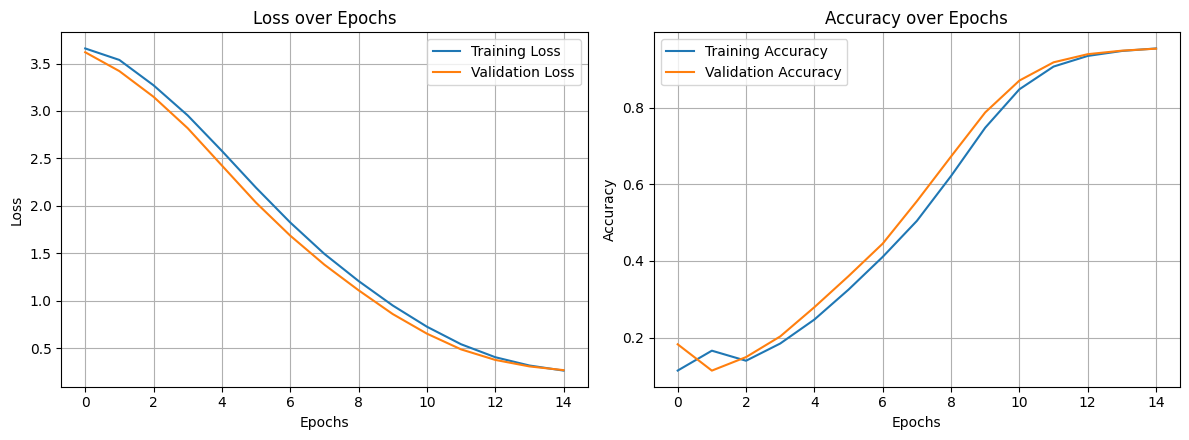

In [17]:
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],       label='Validation Loss')   # TODO (Q4a): val loss key
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'],       label='Validation Accuracy')  # TODO (Q4b): val acc key
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()


Q. Do the training and validation curves stay close together? What would a big gap between them have told you?
* **Answer**: Yes, the training and validation curves stay very close together (both ending around 95% accuracy and 0.26 loss). A big gap between them (where training accuracy is much higher than validation accuracy) would have indicated **overfitting**, meaning the model was memorizing the training samples rather than generalizing.

In [21]:
def generate_music(model, start_sequence, num_generated_notes=40):
    generated = []
    current_sequence = start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)

        # Q5a) pick the most likely note at the LAST time step
        next_note =np.argmax(pred[:, -1, :], axis=-1)# TODO (Q5a): np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b) slide the window: drop the first step, append the new note (one-hot)
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence =np.concatenate([current_sequence[:, 1:, :], oh], axis=1)    # TODO (Q5b): np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated

# seed window (given)
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)

Generated: [37, 37, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20]


Q. At each step, which time-step’s prediction do you keep, and how do you update the input window for the next step?
* **Answer**: We keep the prediction of the **last** timestep (`pred[:, -1, :]`). To update the sliding input window, we drop the very first timestep of our sequence (`current_sequence[:, 1:, :]`) and concatenate the newly predicted, one-hot encoded note to the end (`axis=1`).

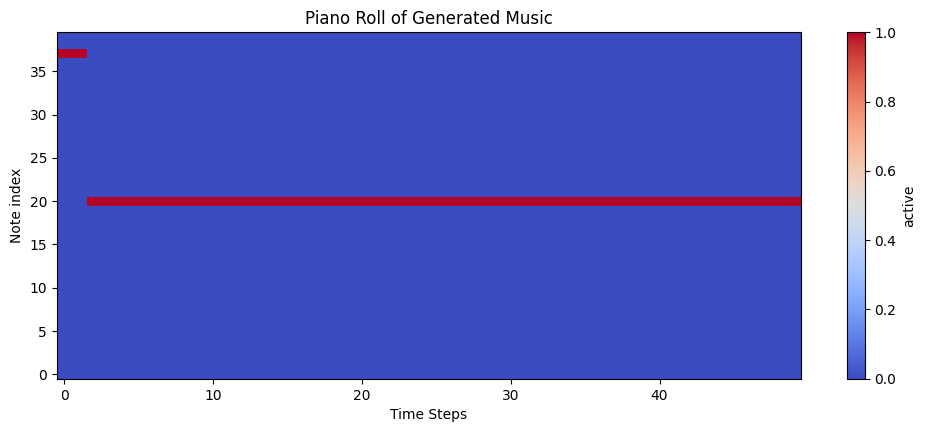

In [22]:
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1   # TODO (Q6): which row is the active note at time t?

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()

Q. What does one column of the piano-roll represent, and why is exactly one cell active in each column?
* **Answer**: Each column represents a single time step. Exactly one cell is active because our sequence consists of monophonic music (one note played at a time), so only a single note index is active (value of 1) at any given moment.

In [23]:
import numpy as np
from IPython.display import Audio
audio = np.concatenate([np.sin(2 * np.pi * (440.0 * (2.0 ** (((48 + n) - 69.0) / 12.0))) * np.linspace(0, 0.25, 2000, False)) for n in generated_music])
Audio(audio, rate=8000)

You trained on random notes, yet accuracy reached about 95%.

Q. Explain in one line how a bidirectional model can score so high on next-note prediction even with no real pattern. (Think: the answer at step t is the input at step t+1 — and the backward pass has already read it.)

* **Answer**: Because the backward pass of the bidirectional model reads the sequence from end to beginning, meaning at step $t$ it already has direct look-ahead access to future steps, essentially "cheating" by reading the target answer from the backward inputs.